In [1]:
!pip install -q yfinance

In [2]:
import yfinance as yf
import pandas as pd

tickers = ["RELIANCE.NS", "HDFCBANK.NS", "INFY.NS", "ITC.NS", "SUNPHARMA.NS",
           "LT.NS", "MARUTI.NS", "TATASTEEL.NS", "BHARTIARTL.NS", "ASIANPAINT.NS"]

prices = yf.download(tickers, start="2016-01-01", end="2026-10-29",
                     auto_adjust=True, progress=False)["Close"]

print(prices.shape)        # (number of days, number of stocks)
print(prices.isna().sum()) # missing values per stock
prices.tail()

(2673, 10)
Ticker
ASIANPAINT.NS    0
BHARTIARTL.NS    0
HDFCBANK.NS      0
INFY.NS          0
ITC.NS           0
LT.NS            0
MARUTI.NS        0
RELIANCE.NS      0
SUNPHARMA.NS     0
TATASTEEL.NS     0
dtype: int64


Ticker,ASIANPAINT.NS,BHARTIARTL.NS,HDFCBANK.NS,INFY.NS,ITC.NS,LT.NS,MARUTI.NS,RELIANCE.NS,SUNPHARMA.NS,TATASTEEL.NS
Date,,,,,,,,,,
2026-10-22,2284.800049,1895.000000,694.049988,1153.349976,258.899994,3638.300049,11170.0,1184.500000,1758.000000,172.330002
2026-10-23,2307.000000,1892.099976,692.799988,1153.800049,257.899994,3647.000000,11230.0,1190.000000,1748.000000,167.669998
2026-10-26,2322.000000,1917.500000,688.049988,1166.000000,260.500000,3680.000000,11220.0,1201.800049,1740.000000,169.940002
2026-10-27,2277.000000,1978.800049,680.200012,1163.000000,260.000000,3665.100098,11450.0,1196.199951,1751.199951,171.419998
2026-10-28,2284.600098,1948.099976,685.299988,1123.150024,259.500000,3801.300049,11579.0,1158.000000,1757.500000,169.270004


<Axes: title={'center': 'Growth of ₹1 invested on 1 Jan 2016'}, xlabel='Date'>

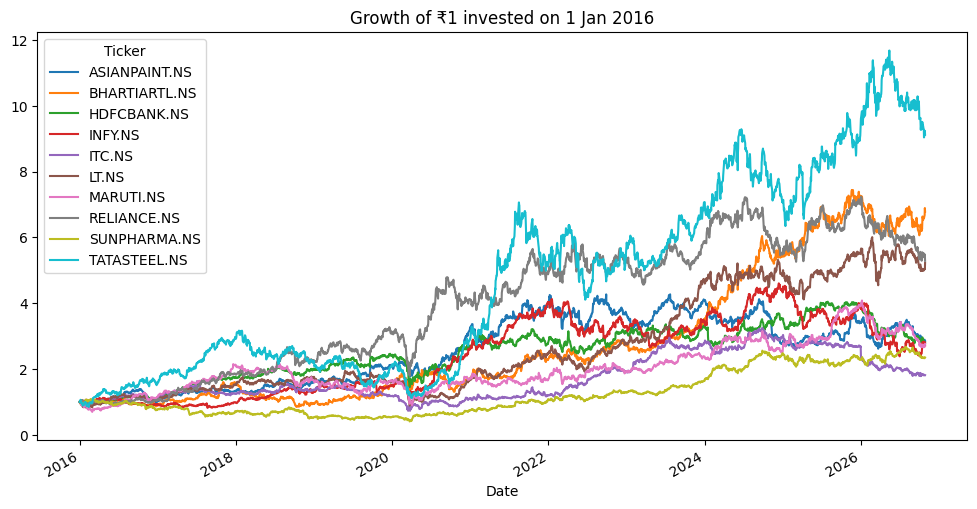

In [3]:
(prices / prices.iloc[0]).plot(figsize=(12, 6),
                               title="Growth of ₹1 invested on 1 Jan 2016")

In [4]:
prices.to_csv("prices.csv")
from google.colab import files
files.download("prices.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
import numpy as np
prices = pd.read_csv("prices.csv", index_col="Date", parse_dates=True)  # if Colab restarted
log_ret = np.log(prices / prices.shift(1)).dropna()

mu  = log_ret.mean() * 252           # annual expected return
cov = log_ret.cov() * 252            # annual covariance matrix
vol = np.sqrt(np.diag(cov))          # annual volatility per stock

summary = pd.DataFrame({"Annual return": mu, "Annual volatility": vol}).sort_values("Annual return")
print(summary.round(3))

               Annual return  Annual volatility
ITC.NS                 0.056              0.241
SUNPHARMA.NS           0.081              0.271
INFY.NS                0.094              0.270
MARUTI.NS              0.096              0.275
HDFCBANK.NS            0.097              0.226
ASIANPAINT.NS          0.099              0.243
LT.NS                  0.156              0.266
RELIANCE.NS            0.157              0.267
BHARTIARTL.NS          0.181              0.286
TATASTEEL.NS           0.209              0.351


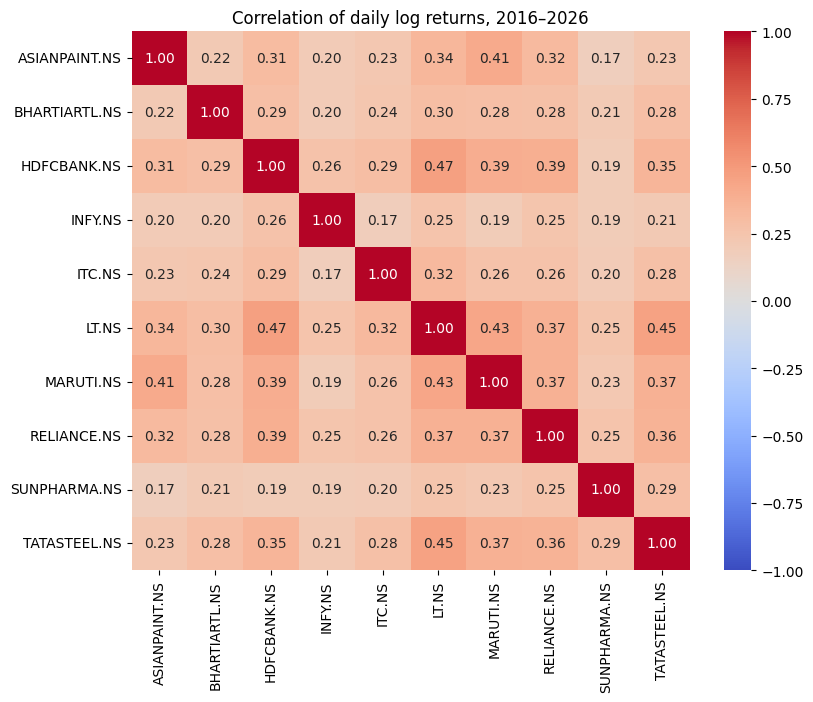

<Figure size 640x480 with 0 Axes>

In [24]:
import seaborn as sns, matplotlib.pyplot as plt
plt.figure(figsize=(9, 7))
sns.heatmap(log_ret.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of daily log returns, 2016–2026"); plt.show()
plt.savefig("figures/correlation.png", dpi=150, bbox_inches="tight")

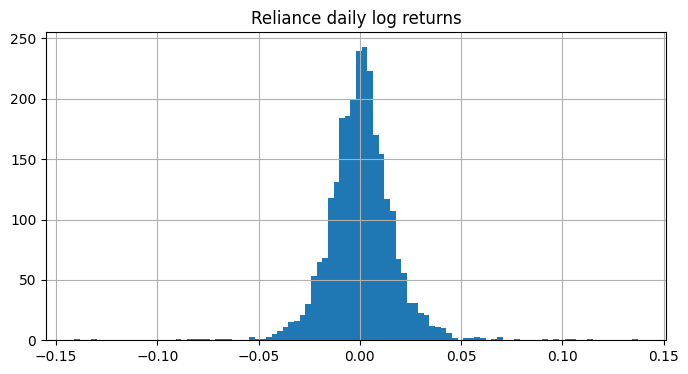

<Figure size 640x480 with 0 Axes>

In [25]:
log_ret["RELIANCE.NS"].hist(bins=100, figsize=(8, 4))
plt.title("Reliance daily log returns"); plt.show()


In [9]:
print(log_ret.kurt().round(1).sort_values())

TATASTEEL.NS      3.4
BHARTIARTL.NS     4.1
SUNPHARMA.NS      5.2
ASIANPAINT.NS     6.5
RELIANCE.NS       8.8
INFY.NS           9.2
HDFCBANK.NS      10.2
LT.NS            10.5
MARUTI.NS        10.5
ITC.NS           10.8
dtype: float64


In [14]:
from scipy.optimize import minimize

n  = len(mu)
rf = 0.059337   # 91-day T-bill, CCIL indicative YTM, 29 Oct 2026

def port_ret(w):   return w @ mu
def port_vol(w):   return np.sqrt(w @ cov @ w)
def neg_sharpe(w): return -(port_ret(w) - rf) / port_vol(w)

cons   = {"type": "eq", "fun": lambda w: w.sum() - 1}   # weights sum to 1
bounds = [(0, 1)] * n                                    # no short selling
w0     = np.ones(n) / n                                  # start from equal weights

w_minvar = minimize(port_vol,   w0, bounds=bounds, constraints=cons).x
w_sharpe = minimize(neg_sharpe, w0, bounds=bounds, constraints=cons).x

weights = pd.DataFrame({"Min variance": w_minvar, "Max Sharpe": w_sharpe}, index=mu.index)
print(weights.round(3))
print()
for name, w in [("Equal weight", w0), ("Min variance", w_minvar), ("Max Sharpe", w_sharpe)]:
    print(f"{name:13s} return {port_ret(w):.3f}  vol {port_vol(w):.3f}  Sharpe {-neg_sharpe(w):.2f}")

               Min variance  Max Sharpe
ASIANPAINT.NS         0.172       0.000
BHARTIARTL.NS         0.087       0.364
HDFCBANK.NS           0.171       0.000
INFY.NS               0.142       0.000
ITC.NS                0.188       0.000
LT.NS                 0.006       0.156
MARUTI.NS             0.030       0.000
RELIANCE.NS           0.053       0.226
SUNPHARMA.NS          0.152       0.000
TATASTEEL.NS          0.000       0.254

Equal weight  return 0.122  vol 0.161  Sharpe 0.39
Min variance  return 0.097  vol 0.150  Sharpe 0.25
Max Sharpe    return 0.178  vol 0.211  Sharpe 0.56


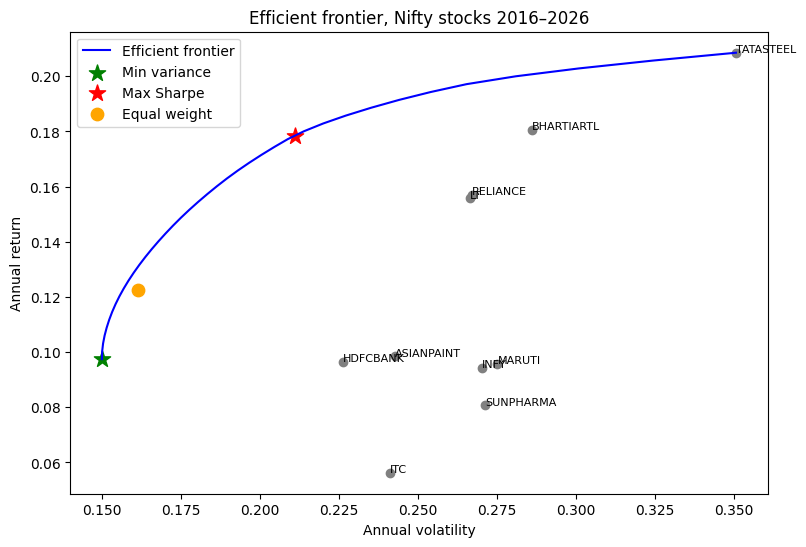

<Figure size 640x480 with 0 Axes>

In [27]:
# Efficient frontier: lowest risk for each target return
targets  = np.linspace(port_ret(w_minvar), mu.max(), 40)
frontier = []
for t in targets:
    c = [cons, {"type": "eq", "fun": lambda w, t=t: port_ret(w) - t}]
    frontier.append(port_vol(minimize(port_vol, w0, bounds=bounds, constraints=c).x))

plt.figure(figsize=(9, 6))
plt.plot(frontier, targets, "b-", label="Efficient frontier")
plt.scatter(vol, mu, c="grey")
for i, t in enumerate(mu.index):
    plt.annotate(t.replace(".NS", ""), (vol[i], mu.iloc[i]), fontsize=8)
plt.scatter(port_vol(w_minvar), port_ret(w_minvar), c="green", s=150, marker="*", label="Min variance")
plt.scatter(port_vol(w_sharpe), port_ret(w_sharpe), c="red",   s=150, marker="*", label="Max Sharpe")
plt.scatter(port_vol(w0),       port_ret(w0),       c="orange", s=80,               label="Equal weight")
plt.xlabel("Annual volatility"); plt.ylabel("Annual return")
plt.title("Efficient frontier, Nifty stocks 2016–2026"); plt.legend(); plt.show()
plt.savefig("figures/frontier.png", dpi=150, bbox_inches="tight")

In [16]:
def max_sharpe_weights(ret, rf=rf):
    m = ret.mean() * 252
    C = ret.cov() * 252
    k = len(m)
    obj = lambda w: -((w @ m) - rf) / np.sqrt(w @ C @ w)
    res = minimize(obj, np.ones(k) / k, bounds=[(0, 1)] * k,
                   constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
    return pd.Series(res.x, index=ret.columns)

end = log_ret.index[-1]
windows = {}
for yrs in [1, 3, 5, 10]:
    sub = log_ret[log_ret.index > end - pd.DateOffset(years=yrs)]
    windows[f"{yrs}y ({len(sub)} days)"] = max_sharpe_weights(sub)

window_w = pd.DataFrame(windows)
print(window_w.round(2))
print("\nStocks used (>1%):", (window_w > 0.01).sum().to_dict())

               1y (247 days)  3y (740 days)  5y (1235 days)  10y (2470 days)
ASIANPAINT.NS            0.0           0.00            0.00             0.00
BHARTIARTL.NS            0.0           0.72            0.54             0.46
HDFCBANK.NS              0.0           0.00            0.00             0.00
INFY.NS                  0.0           0.00            0.00             0.01
ITC.NS                   0.0           0.00            0.00             0.00
LT.NS                    0.0           0.00            0.11             0.17
MARUTI.NS                0.0           0.00            0.00             0.00
RELIANCE.NS              0.0           0.00            0.00             0.26
SUNPHARMA.NS             1.0           0.28            0.35             0.00
TATASTEEL.NS             0.0           0.00            0.00             0.10

Stocks used (>1%): {'1y (247 days)': 1, '3y (740 days)': 2, '5y (1235 days)': 3, '10y (2470 days)': 4}


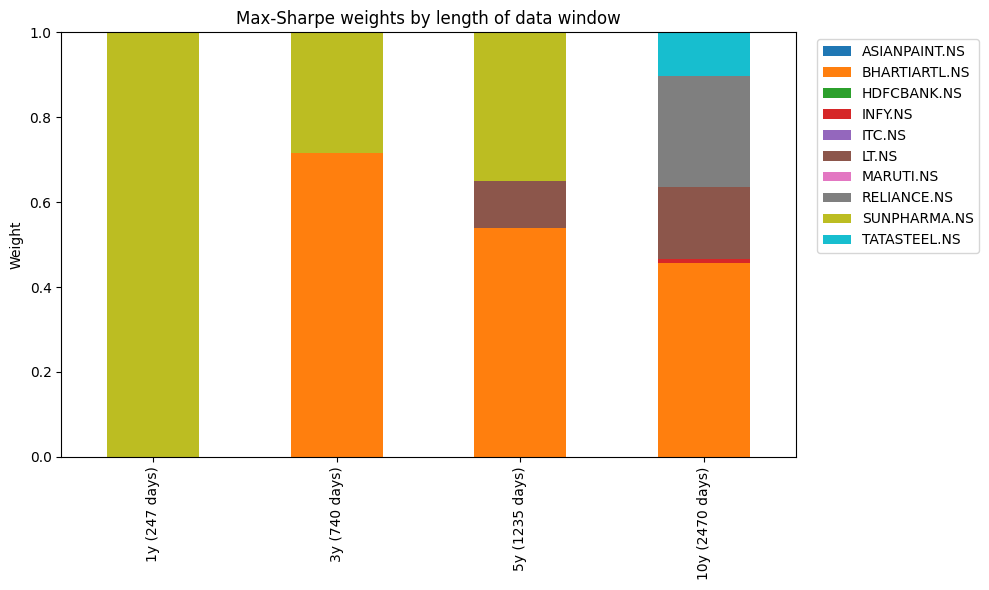

<Figure size 640x480 with 0 Axes>

In [26]:
window_w.T.plot(kind="bar", stacked=True, figsize=(10, 6), colormap="tab10")
plt.ylabel("Weight"); plt.title("Max-Sharpe weights by length of data window")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()
plt.savefig("figures/window_weights.png", dpi=150, bbox_inches="tight")

In [18]:
def min_var_weights(ret):
    C = ret.cov() * 252
    k = C.shape[0]
    res = minimize(lambda w: np.sqrt(w @ C.values @ w), np.ones(k) / k,
                   bounds=[(0, 1)] * k,
                   constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
    return pd.Series(res.x, index=ret.columns)

rng = np.random.default_rng(42)          # fixed seed so results are reproducible
B = 500
boot_sharpe, boot_minvar = [], []
for b in range(B):
    idx = rng.integers(0, len(log_ret), len(log_ret))
    sample = log_ret.iloc[idx]
    boot_sharpe.append(max_sharpe_weights(sample))
    boot_minvar.append(min_var_weights(sample))

boot_sharpe = pd.DataFrame(boot_sharpe)
boot_minvar = pd.DataFrame(boot_minvar)

def summarise(df):
    return pd.DataFrame({"mean": df.mean(), "5%": df.quantile(0.05),
                         "95%": df.quantile(0.95), "% of runs used": (df > 0.01).mean()})

print("MAX SHARPE\n", summarise(boot_sharpe).round(2))
print("\nMIN VARIANCE\n", summarise(boot_minvar).round(2))

MAX SHARPE
                mean   5%   95%  % of runs used
ASIANPAINT.NS  0.08  0.0  0.42            0.31
BHARTIARTL.NS  0.22  0.0  0.64            0.73
HDFCBANK.NS    0.05  0.0  0.32            0.20
INFY.NS        0.09  0.0  0.44            0.38
ITC.NS         0.03  0.0  0.19            0.15
LT.NS          0.13  0.0  0.52            0.47
MARUTI.NS      0.03  0.0  0.21            0.20
RELIANCE.NS    0.17  0.0  0.60            0.60
SUNPHARMA.NS   0.04  0.0  0.25            0.26
TATASTEEL.NS   0.17  0.0  0.63            0.63

MIN VARIANCE
                mean    5%   95%  % of runs used
ASIANPAINT.NS  0.17  0.14  0.20            1.00
BHARTIARTL.NS  0.09  0.06  0.11            1.00
HDFCBANK.NS    0.17  0.13  0.21            1.00
INFY.NS        0.14  0.12  0.17            1.00
ITC.NS         0.19  0.15  0.23            1.00
LT.NS          0.01  0.00  0.04            0.41
MARUTI.NS      0.03  0.00  0.06            0.82
RELIANCE.NS    0.05  0.02  0.08            0.99
SUNPHARMA.NS   0.15  0.1

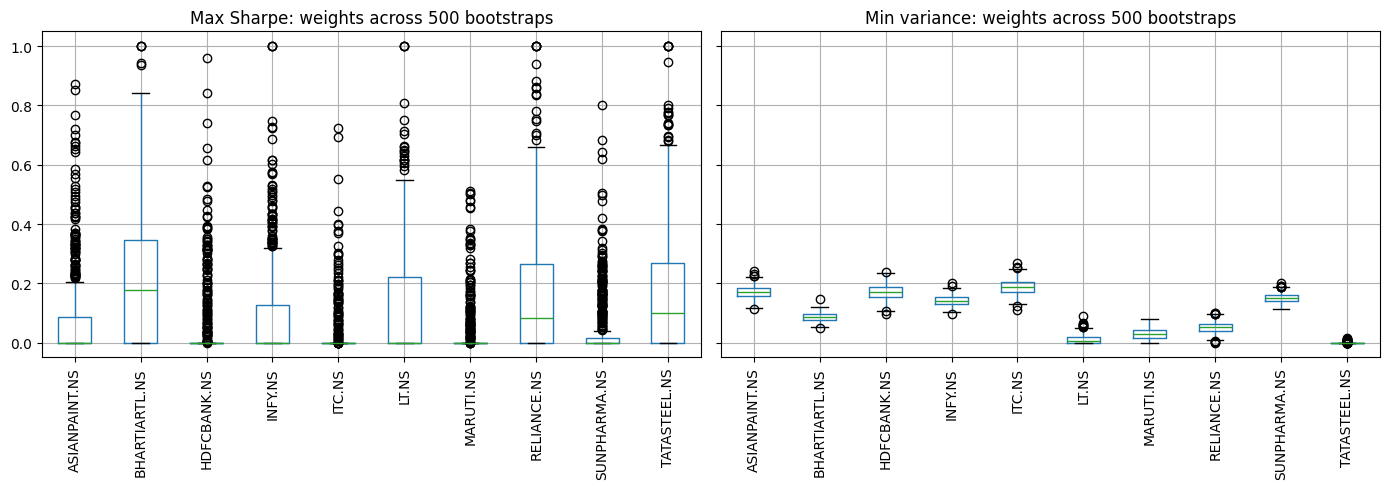

<Figure size 640x480 with 0 Axes>

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
boot_sharpe.boxplot(ax=axes[0], rot=90); axes[0].set_title("Max Sharpe: weights across 500 bootstraps")
boot_minvar.boxplot(ax=axes[1], rot=90); axes[1].set_title("Min variance: weights across 500 bootstraps")
plt.tight_layout(); plt.show()
plt.savefig("figures/bootstrap.png", dpi=150, bbox_inches="tight")

In [20]:
train = log_ret[log_ret.index <  "2023-01-01"]
test_simple = prices.pct_change().dropna()
test_simple = test_simple[test_simple.index >= "2023-01-01"]

strategies = {
    "Equal weight": pd.Series(np.ones(n) / n, index=log_ret.columns),
    "Min variance": min_var_weights(train),
    "Max Sharpe":   max_sharpe_weights(train),
}
print(pd.DataFrame(strategies).round(2))

def perf(daily):
    wealth = (1 + daily).cumprod()
    years  = len(daily) / 252
    cagr   = wealth.iloc[-1] ** (1 / years) - 1
    vol    = daily.std() * np.sqrt(252)
    mdd    = (wealth / wealth.cummax() - 1).min()
    return pd.Series({"CAGR": cagr, "Volatility": vol,
                      "Sharpe": (cagr - rf) / vol, "Max drawdown": mdd})

daily_ret = {k: test_simple @ w for k, w in strategies.items()}
print("\nTEST PERIOD 2023 → today")
print(pd.DataFrame({k: perf(v) for k, v in daily_ret.items()}).T.round(3))

               Equal weight  Min variance  Max Sharpe
ASIANPAINT.NS           0.1          0.18        0.26
BHARTIARTL.NS           0.1          0.08        0.00
HDFCBANK.NS             0.1          0.18        0.09
INFY.NS                 0.1          0.17        0.17
ITC.NS                  0.1          0.18        0.00
LT.NS                   0.1          0.01        0.00
MARUTI.NS               0.1          0.00        0.00
RELIANCE.NS             0.1          0.06        0.34
SUNPHARMA.NS            0.1          0.13        0.00
TATASTEEL.NS            0.1          0.00        0.15

TEST PERIOD 2023 → today
               CAGR  Volatility  Sharpe  Max drawdown
Equal weight  0.084       0.125   0.195        -0.195
Min variance  0.029       0.120  -0.252        -0.256
Max Sharpe    0.006       0.146  -0.365        -0.228


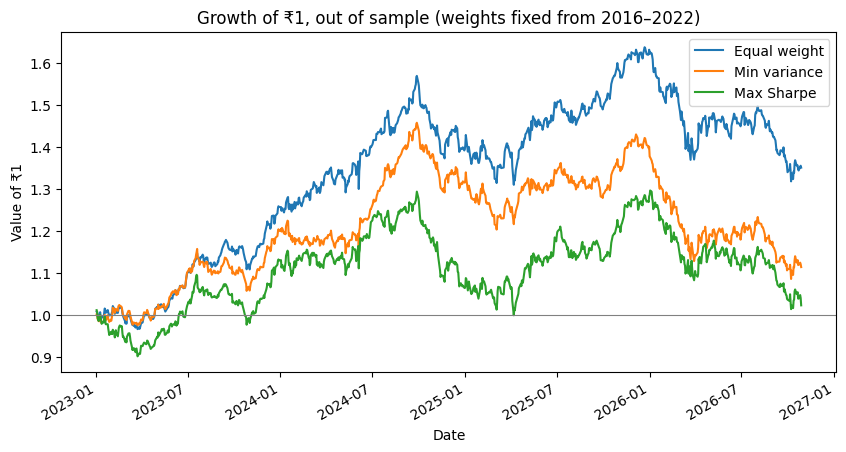

<Figure size 640x480 with 0 Axes>

In [29]:
plt.figure(figsize=(10, 5))
for k, v in daily_ret.items():
    (1 + v).cumprod().plot(label=k)
plt.axhline(1, color="grey", lw=0.8)
plt.title("Growth of ₹1, out of sample (weights fixed from 2016–2022)")
plt.ylabel("Value of ₹1"); plt.legend(); plt.show()
plt.savefig("figures/out_of_sample.png", dpi=150, bbox_inches="tight")

In [22]:
print(((1 + test_simple).prod() ** (252 / len(test_simple)) - 1).sort_values().round(3))

ASIANPAINT.NS   -0.068
INFY.NS         -0.049
HDFCBANK.NS     -0.031
ITC.NS          -0.014
RELIANCE.NS      0.000
MARUTI.NS        0.101
TATASTEEL.NS     0.144
SUNPHARMA.NS     0.174
LT.NS            0.186
BHARTIARTL.NS    0.276
dtype: float64


In [23]:
import os; os.makedirs("figures", exist_ok=True)

In [30]:
!zip -r figures.zip figures
from google.colab import files; files.download("figures.zip")

  adding: figures/ (stored 0%)
  adding: figures/frontier.png (deflated 95%)
  adding: figures/correlation.png (deflated 95%)
  adding: figures/window_weights.png (deflated 95%)
  adding: figures/bootstrap.png (deflated 95%)
  adding: figures/out_of_sample.png (deflated 95%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>